# Mastery-triggered curriculum — analysis

Compare fixed-late, fixed-early, and performance-triggered stage transitions under the same 9,000-update, constant-LR budget. The gate uses a scene-disjoint **progress-dev** subset; the main analysis uses **heldout-dev**. No model training occurs in this notebook.

**Report outputs:** figures and summary tables are saved under `outputs/medium_world/experiments/mastery_progression/`.

In [1]:
from pathlib import Path
import json, sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

PROJECT_ROOT = Path().cwd().parent.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

path = PROJECT_ROOT / 'outputs/medium_world/experiments/mastery_progression/schedule_comparison.json'
report = json.loads(path.read_text(encoding='utf-8'))
runs = report['runs']
POLICIES = ('fixed_late', 'fixed_early', 'mastery')
TASKS = ('color', 'shape', 'conjunction', 'pair')
print('Seeds:', sorted({r['seed'] for r in runs}), '| Updates:', report['config']['total_updates'])
print('Attribute targets:', report['config']['attribute_targets'])
print('Conjunction targets:', report['config']['conjunction_targets'])
OUTPUT_DIR = path.parent

def save_figure(fig, filename):
    fig.savefig(OUTPUT_DIR / f'{filename}.png', dpi=300,
                bbox_inches='tight', facecolor='white')

Seeds: [42, 43, 44, 45, 46] | Updates: 9000
Attribute targets: {'color': 0.94, 'shape': 0.7}
Conjunction targets: {'conjunction': 0.77, 'color': 0.91, 'shape': 0.68}


## 1. Did advancement happen through mastery or a stage cap?

Reaching the maximum permitted stage duration is **not** equivalent to satisfying the performance criterion. We therefore begin with the actual transition step and reason for each seed, before looking at accuracy.

In [2]:
transitions = pd.DataFrame([{
    'seed': r['seed'], 'policy': r['policy'],
    'attributes_end': r['transitions'][0]['step'],
    'attributes_reason': r['transitions'][0]['reason'],
    'conjunction_end': r['transitions'][1]['step'],
    'conjunction_reason': r['transitions'][1]['reason'],
    'common_mixed': r['transitions'][2]['step']
} for r in runs])
transitions.to_csv(OUTPUT_DIR / 'stage_transitions.csv', index=False)
display(transitions.sort_values(['seed', 'policy']).reset_index(drop=True))
display(transitions[transitions.policy == 'mastery']
        [['attributes_reason', 'conjunction_reason']].apply(pd.Series.value_counts).fillna(0))

,seed,policy,attributes_end,attributes_reason,conjunction_end,conjunction_reason,common_mixed
0,42,fixed_early,1400,fixed_step,2200,fixed_step,7200
1,42,fixed_late,3000,fixed_step,5000,fixed_step,7200
2,42,mastery,2700,mastery,3500,mastery,7200
3,43,fixed_early,1400,fixed_step,2200,fixed_step,7200
4,43,fixed_late,3000,fixed_step,5000,fixed_step,7200
5,43,mastery,3000,stage_cap,5400,stage_cap,7200
6,44,fixed_early,1400,fixed_step,2200,fixed_step,7200
7,44,fixed_late,3000,fixed_step,5000,fixed_step,7200
8,44,mastery,3000,stage_cap,4000,mastery,7200
9,45,fixed_early,1400,fixed_step,2200,fixed_step,7200


,attributes_reason,conjunction_reason
mastery,1,3
stage_cap,4,2


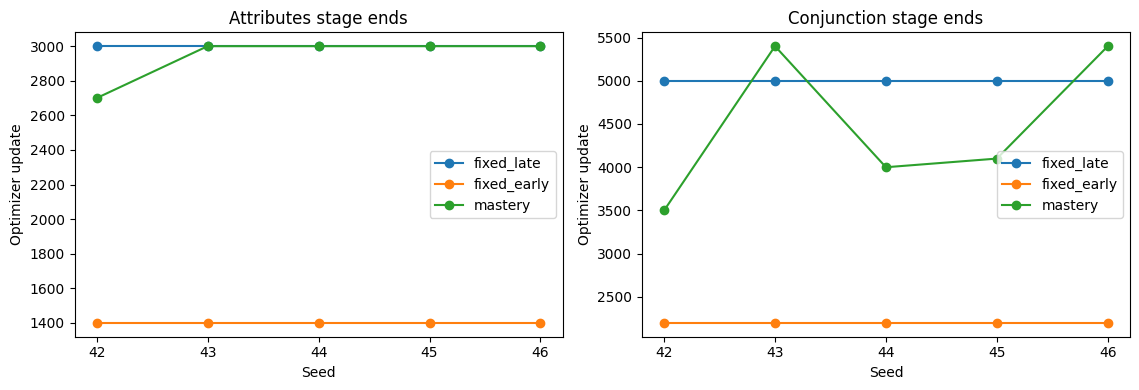

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for ax, stage, column in zip(axes, ('attributes', 'conjunction'),
                             ('attributes_end', 'conjunction_end')):
    for policy in POLICIES:
        part = transitions[transitions.policy == policy].sort_values('seed')
        ax.plot(part['seed'], part[column], marker='o', label=policy)
    ax.set(title=f'{stage.title()} stage ends', xlabel='Seed',
           ylabel='Optimizer update', xticks=sorted(transitions.seed.unique()))
    ax.legend()
plt.tight_layout()
save_figure(fig, 'actual_stage_transition_steps')
plt.show()

## 2. What was the model able to demonstrate at transition?

The gate averages the past three progress-dev evaluations and requires two qualifying checks. The targets are researcher-defined, and success on a small progress set is not a guarantee of out-of-sample competence. We display single-checkpoint progress and held-out performance at each transition; **these are not the smoothed threshold values**.

In [4]:
gate_rows = []
for r in runs:
    if r['policy'] != 'mastery':
        continue
    for tr in r['transitions'][:2]:
        h = next(h for h in r['history'] if h['step'] == tr['step'])
        gate_rows.append({
            'seed': r['seed'], 'stage': tr['from'], 'step': tr['step'],
            'reason': tr['reason'],
            'shape_progress': 100 * h['progress_dev']['by_template']['shape'],
            'shape_heldout': 100 * h['heldout_dev']['by_template']['shape'],
            'color_progress': 100 * h['progress_dev']['by_template']['color'],
            'conjunction_progress': 100 * h['progress_dev']['by_template']['conjunction']
        })
display(pd.DataFrame(gate_rows).sort_values(['stage', 'seed']).round(2))

,seed,stage,step,reason,shape_progress,shape_heldout,color_progress,conjunction_progress
0,42,attributes,2700,mastery,71.07,62.22,99.22,78.91
2,43,attributes,3000,stage_cap,63.64,57.78,99.22,79.69
4,44,attributes,3000,stage_cap,69.42,58.52,99.22,78.12
6,45,attributes,3000,stage_cap,67.77,57.78,99.22,72.66
8,46,attributes,3000,stage_cap,64.46,58.52,98.44,64.06
1,42,conjunction,3500,mastery,78.51,61.48,99.22,78.91
3,43,conjunction,5400,stage_cap,67.77,62.22,100.00,77.34
5,44,conjunction,4000,mastery,70.25,64.44,98.44,81.25
7,45,conjunction,4100,mastery,70.25,62.22,99.22,78.12
9,46,conjunction,5400,stage_cap,68.60,60.00,98.44,77.34


## 3. Final generalization and learning-curve area

The primary final metric is **held-out ID binding accuracy**, not the progress set used to choose transitions. AULC measures average accuracy during the whole 9,000-step budget:

$$\mathrm{AULC}=\frac{1}{T}\sum_i\frac{A(t_i)+A(t_{i-1})}{2}(t_i-t_{i-1}).$$

The development split is scene-disjoint but not task-label-stratified, so also inspect the full ID-dev and balanced OOD-dev results. OOD BCE measures the probability assigned to correct answers, not just the decision accuracy.

In [5]:
def aulc(history, split='heldout_dev', task='pair'):
    steps = np.array([h['step'] for h in history], dtype=float)
    acc = np.array([h[split]['by_template'][task] for h in history])
    return np.sum(np.diff(steps) * (acc[1:] + acc[:-1]) / 2) / (steps[-1] - steps[0])

rows = []
for r in runs:
    f = r['final']
    rows.append({
        'seed': r['seed'], 'policy': r['policy'],
        'heldout_pair': 100 * f['heldout_dev']['by_template']['pair'],
        'id_pair': 100 * f['id_dev']['by_template']['pair'],
        'ood_pair': 100 * f['ood_dev']['by_template']['pair'],
        'ood_bce': f['ood_dev']['loss'],
        'heldout_overall': 100 * f['heldout_dev']['accuracy'],
        'shape': 100 * f['heldout_dev']['by_template']['shape'],
        'color': 100 * f['heldout_dev']['by_template']['color'],
        'conjunction': 100 * f['heldout_dev']['by_template']['conjunction'],
        'heldout_pair_aulc': 100 * aulc(r['history']),
        'id_pair_aulc': 100 * r['id_pair_aulc']
    })
final = pd.DataFrame(rows)
metrics = ['heldout_pair', 'id_pair', 'ood_pair', 'ood_bce',
           'heldout_pair_aulc', 'heldout_overall', 'shape']
final.to_csv(OUTPUT_DIR / 'final_by_seed.csv', index=False)
display(final.sort_values(['seed', 'policy']).reset_index(drop=True).round(2))
display(final.groupby('policy')[metrics].agg(['mean', 'std']).reindex(POLICIES).round(2))

,seed,policy,heldout_pair,id_pair,ood_pair,ood_bce,heldout_overall,shape,color,conjunction,heldout_pair_aulc,id_pair_aulc
0,42,fixed_early,59.50,61.72,57.50,0.75,75.00,60.00,100.00,80.47,53.98,56.03
1,42,fixed_late,59.50,62.89,54.25,0.76,76.17,61.48,99.22,84.38,51.12,55.58
2,42,mastery,61.98,65.62,51.25,0.82,76.95,62.22,99.22,84.38,53.44,56.79
3,43,fixed_early,61.16,58.59,55.50,0.73,76.76,64.44,100.00,81.25,52.47,54.97
4,43,fixed_late,60.33,60.16,53.50,0.80,75.59,62.96,100.00,78.91,51.31,53.98
5,43,mastery,62.81,60.16,51.25,0.82,75.78,61.48,100.00,78.91,50.34,53.93
6,44,fixed_early,61.98,62.50,51.00,1.03,77.15,64.44,100.00,82.03,50.52,54.25
7,44,fixed_late,57.02,57.03,56.50,0.77,75.20,62.96,99.22,81.25,48.17,52.65
8,44,mastery,58.68,57.81,56.25,0.85,75.59,63.70,99.22,80.47,49.41,53.00
9,45,fixed_early,63.64,65.62,57.75,0.76,77.15,68.15,100.00,76.56,58.59,60.05


heldout_pair       id_pair       ood_pair       ood_bce        \
                    mean   std    mean   std     mean   std    mean   std   
policy                                                                      
fixed_late         60.66  3.72   61.80  3.60    55.65  1.74    0.79  0.03   
fixed_early        61.16  1.75   61.88  2.56    55.25  2.74    0.82  0.13   
mastery            60.83  2.38   62.03  3.62    54.20  2.93    0.84  0.02   

            heldout_pair_aulc       heldout_overall        shape        
                         mean   std            mean   std   mean   std  
policy                                                                  
fixed_late              51.96  2.71           75.70  0.90  62.52  0.99  
fixed_early             53.85  2.98           76.37  0.95  64.59  2.98  
mastery                 52.75  2.78           75.86  1.58  62.96  3.31

## Final binding and generalization — report figure

Compare fixed-late, fixed-early and mastery under the same total budget. The internal held-out binding subset has an unequal Yes/No balance, so the OOD 50% reference line is not automatically the held-out subset baseline.

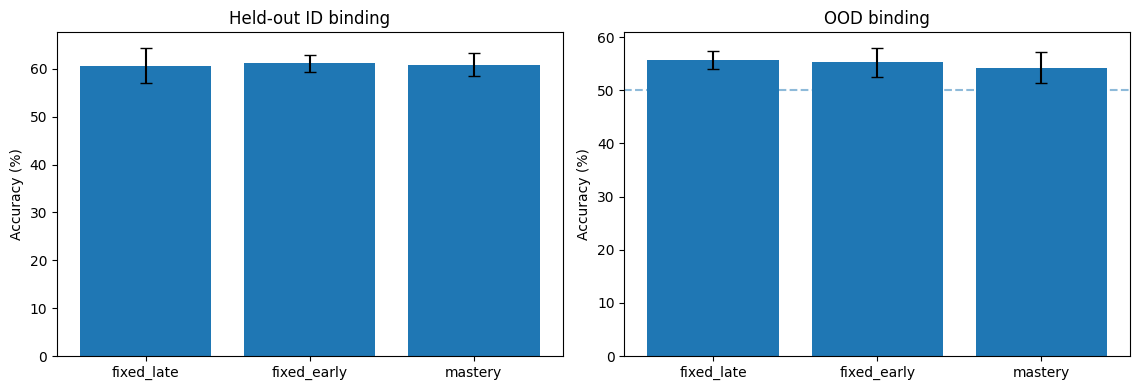

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4))
for ax, metric, title in zip(axes, ('heldout_pair', 'ood_pair'),
                              ('Held-out ID binding', 'OOD binding')):
    stats = final.groupby('policy')[metric].agg(['mean', 'std']).reindex(POLICIES)
    ax.bar(POLICIES, stats['mean'], yerr=stats['std'], capsize=4)
    ax.set(title=title, ylabel='Accuracy (%)')
    if metric == 'ood_pair':
        ax.axhline(50, linestyle='--', alpha=.5)
plt.tight_layout()
save_figure(fig, 'final_binding_id_ood')
plt.show()

## 4. Do paired seeds favor a mastery-based decision?

For paired seed $s$, $\Delta_s=A_s(\mathrm{mastery})-A_s(\mathrm{fixed})$. Positive differences favor mastery; report the number of favorable seeds as well as the mean. A small advantage across five seeds does not justify a universal claim.

In [7]:
comparisons = (('mastery', 'fixed_early'), ('mastery', 'fixed_late'),
               ('fixed_early', 'fixed_late'))
differences = []
for first, second in comparisons:
    for metric in ('heldout_pair', 'id_pair', 'ood_pair', 'heldout_pair_aulc',
                   'heldout_overall', 'shape', 'ood_bce'):
        pivot = final.pivot(index='seed', columns='policy', values=metric)
        delta = pivot[first] - pivot[second]
        differences.append({'contrast': first + ' − ' + second, 'metric': metric,
                            'mean_difference': delta.mean(), 'sd': delta.std(),
                            'wins': (delta > 0).sum()})
pd.DataFrame(differences).to_csv(OUTPUT_DIR / 'paired_differences.csv', index=False)
display(pd.DataFrame(differences).round(3))

,contrast,metric,mean_difference,sd,wins
0,mastery − fixed_early,heldout_pair,-0.331,2.381,2
1,mastery − fixed_early,id_pair,0.156,3.157,3
2,mastery − fixed_early,ood_pair,-1.050,5.007,2
3,mastery − fixed_early,heldout_pair_aulc,-1.098,1.466,1
4,mastery − fixed_early,heldout_overall,-0.508,1.700,2
5,mastery − fixed_early,shape,-1.630,3.370,1
6,mastery − fixed_early,ood_bce,0.015,0.121,3
7,mastery − fixed_late,heldout_pair,0.165,2.945,3
8,mastery − fixed_late,id_pair,0.234,1.648,2
9,mastery − fixed_late,ood_pair,-1.450,1.292,0


## 5. When did binding and shape accuracy improve?

A fixed-early schedule gives the model more updates **after** introducing binding. These curves plot performance against total optimizer steps, not examples spent specifically on binding. We display held-out binding and shape, and print the mean transition times to interpret the timing shift.

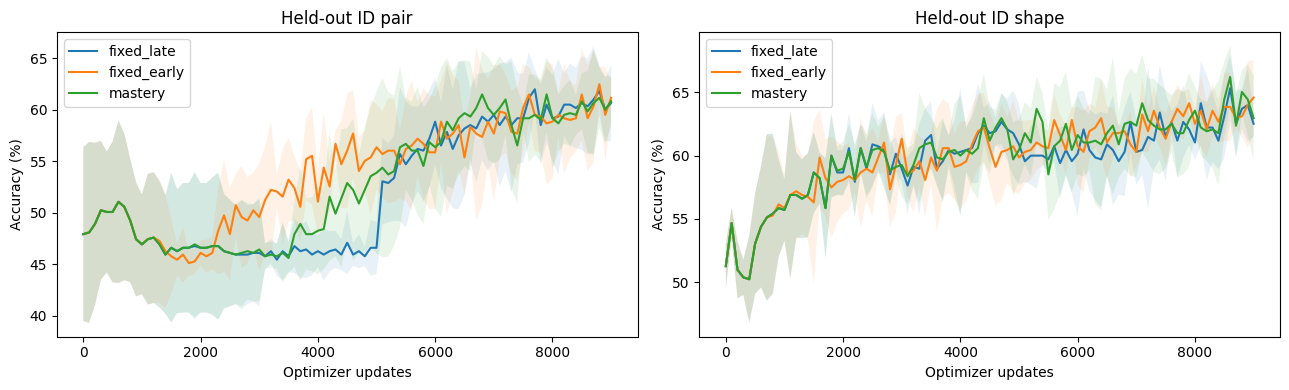

,attributes_end,conjunction_end
policy,,
fixed_early,1400.0,2200.0
fixed_late,3000.0,5000.0
mastery,2940.0,4480.0


In [8]:
curves = pd.DataFrame([{
    'seed': r['seed'], 'policy': r['policy'], 'step': h['step'],
    'pair': 100 * h['heldout_dev']['by_template']['pair'],
    'shape': 100 * h['heldout_dev']['by_template']['shape']
} for r in runs for h in r['history']])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, metric in zip(axes, ('pair', 'shape')):
    for policy in POLICIES:
        curve = curves[curves.policy == policy].groupby('step')[metric].agg(['mean', 'std'])
        ax.plot(curve.index, curve['mean'], label=policy)
        ax.fill_between(curve.index, curve['mean'] - curve['std'],
                        curve['mean'] + curve['std'], alpha=.10)
    ax.set(title='Held-out ID ' + metric, xlabel='Optimizer updates',
           ylabel='Accuracy (%)')
    ax.legend()
plt.tight_layout()
save_figure(fig, 'heldout_pair_shape_learning_curves')
plt.show()
display(transitions.groupby('policy')[['attributes_end', 'conjunction_end']].mean())

## 6. Does quota-based rehearsal remain available?

Equal **total** presentations do not guarantee rehearsal during every stage. If the earlier-task quotas are depleted before the binding stage, binding may become a single-task phase. We measure actual presentation counts rather than assuming replay always occurred.

In [9]:
exposures = []
for r in runs:
    for phase, counts in r['phase_task_presentations'].items():
        total = sum(counts.values())
        replay = total - counts.get('pair', 0) if phase == 'binding' else np.nan
        exposures.append({
            'seed': r['seed'], 'policy': r['policy'], 'phase': phase,
            'total_examples': total, 'pair_examples': counts.get('pair', 0),
            'rehearsal_examples': replay,
            'rehearsal_share': 100 * replay / total if phase == 'binding' else np.nan
        })
exposure = pd.DataFrame(exposures)
exposure.to_csv(OUTPUT_DIR / 'phase_exposure.csv', index=False)
display(exposure[exposure.phase == 'binding']
        .sort_values(['seed', 'policy']).reset_index(drop=True).round(2))

,seed,policy,phase,total_examples,pair_examples,rehearsal_examples,rehearsal_share
0,42,fixed_early,binding,250000,90000,160000.0,64.00
1,42,fixed_late,binding,110000,90000,20000.0,18.18
2,42,mastery,binding,185000,90000,95000.0,51.35
3,43,fixed_early,binding,250000,90000,160000.0,64.00
4,43,fixed_late,binding,110000,90000,20000.0,18.18
5,43,mastery,binding,90000,90000,0.0,0.00
6,44,fixed_early,binding,250000,90000,160000.0,64.00
7,44,fixed_late,binding,110000,90000,20000.0,18.18
8,44,mastery,binding,160000,90000,70000.0,43.75
9,45,fixed_early,binding,250000,90000,160000.0,64.00


## 7. Temporary forgetting and common consolidation

Compare skills when binding is first introduced, just before the common mixed stage (step 7,200), and at the end (step 9,000). These changes describe forgetting/recovery during different task mixtures, **not** a controlled rehearsal-versus-no-rehearsal ablation.

In [10]:
retention = []
for r in runs:
    checkpoints = {h['step']: h for h in r['history']}
    binding_start = r['transitions'][1]['step']
    for task in TASKS:
        begin = 100 * checkpoints[binding_start]['heldout_dev']['by_template'][task]
        before_common = 100 * checkpoints[7200]['heldout_dev']['by_template'][task]
        end = 100 * checkpoints[9000]['heldout_dev']['by_template'][task]
        retention.append({
            'seed': r['seed'], 'policy': r['policy'], 'task': task,
            'during_binding': before_common - begin,
            'during_consolidation': end - before_common
        })
retention = pd.DataFrame(retention)
retention.to_csv(OUTPUT_DIR / 'retention_by_seed.csv', index=False)
display(retention.groupby(['policy', 'task'])
        [['during_binding', 'during_consolidation']].mean().round(2))

during_binding  during_consolidation
policy      task                                             
fixed_early color                  1.56                  0.31
            conjunction           -0.16                  1.41
            pair                  13.55                  1.49
            shape                  3.85                  2.67
fixed_late  color                 -0.78                  0.78
            conjunction           -2.66                  1.72
            pair                  12.73                  1.32
            shape                  0.59                  1.04
mastery     color                 -5.00                  5.31
            conjunction           -3.44                  2.97
            pair                  14.38                 -0.17
            shape                  0.74                  0.15

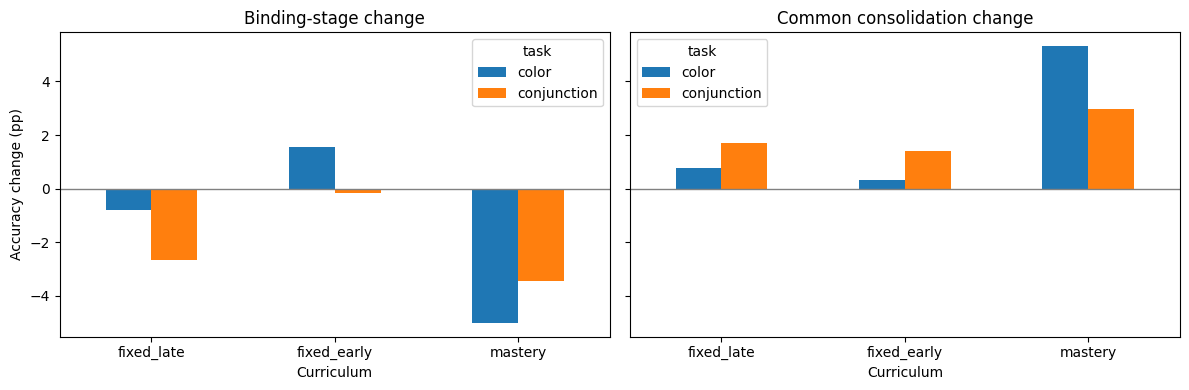

In [11]:
focus = retention[retention.task.isin(('color', 'conjunction'))]
summary = focus.groupby(['policy', 'task'])[['during_binding', 'during_consolidation']].mean()
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, column, title in zip(axes, ('during_binding', 'during_consolidation'),
                             ('Binding-stage change', 'Common consolidation change')):
    values = summary[column].unstack('task').reindex(POLICIES)
    values.plot.bar(ax=ax, rot=0)
    ax.axhline(0, color='gray', linewidth=1)
    ax.set(title=title, xlabel='Curriculum', ylabel='Accuracy change (pp)')
plt.tight_layout()
save_figure(fig, 'retention_and_recovery')
plt.show()

## 8. Stage-by-stage skill profiles with adaptive boundaries

Unlike fixed schedules, the mastery policy transitions at **different updates for different seeds**. Each column below therefore represents the accuracy at the end of a named stage, not a shared global update. This reveals how much of each skill remains when the policy advances.

accuracy_end  change_pp
policy      phase        task                                
fixed_early attributes   color               93.91      42.34
                         conjunction         69.69      19.69
                         pair                46.28      -1.65
                         shape               56.74       5.48
            binding      color               99.53       1.56
                         conjunction         78.28      -0.16
                         pair                59.67      13.55
                         shape               61.93       3.85
            common_mixed color               99.84       0.31
                         conjunction         79.69       1.41
                         pair                61.16       1.49
                         shape               64.59       2.67
            conjunction  color               97.97       4.06
                         conjunction         78.44       8.75
                         pair                46.12      -0.17
                         shape               58.07       1.33
fixed_late  attributes   color               98.91      47.34
                         conjunction         74.84      24.84
                         pair                46.12      -1.82
                         shape               58.96       7.70
            binding      color               98.75      -0.78
                         conjunction         78.28      -2.66
                         pair                59.34      12.73
                         shape               61.48       0.59
            common_mixed color               99.53       0.78
                         conjunction         80.00       1.72
                         pair                60.66       1.32
                         shape               62.52       1.04
            conjunction  color               99.53       0.62
                         conjunction         80.94       6.09
                         pair                46.61       0.50
                         shape               60.89       1.93
mastery     attributes   color               98.75      47.19
                         conjunction         74.84      24.84
                         pair                46.12      -1.82
                         shape               58.96       7.70
            binding      color               94.22      -5.00
                         conjunction         77.03      -3.44
                         pair                60.99      14.38
                         shape               62.81       0.74
            common_mixed color               99.53       5.31
                         conjunction         80.00       2.97
                         pair                60.83      -0.17
                         shape               62.96       0.15
            conjunction  color               99.22       0.47
                         conjunction         80.47       5.62
                         pair                46.61       0.50
                         shape               62.07       3.11

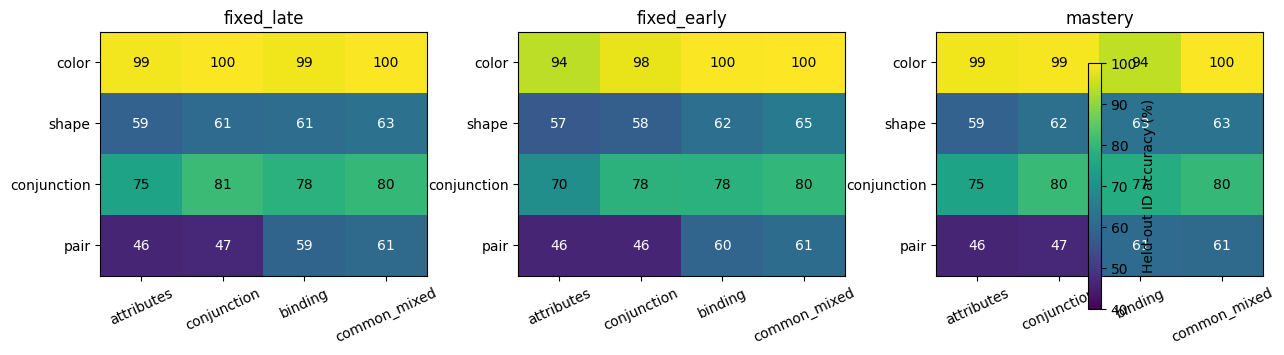

In [12]:
stage_rows = []
for r in runs:
    checkpoints = {h['step']: h for h in r['history']}
    boundaries = [('attributes', r['transitions'][0]['step']),
                  ('conjunction', r['transitions'][1]['step']),
                  ('binding', r['transitions'][2]['step']),
                  ('common_mixed', r['steps_run'])]
    prev = 0
    for phase, end in boundaries:
        for task in TASKS:
            a = 100 * checkpoints[prev]['heldout_dev']['by_template'][task]
            b = 100 * checkpoints[end]['heldout_dev']['by_template'][task]
            stage_rows.append({'seed': r['seed'], 'policy': r['policy'],
                               'phase': phase, 'start': prev, 'end': end,
                               'task': task, 'accuracy_end': b,
                               'change_pp': b - a})
        prev = end
stage_scores = pd.DataFrame(stage_rows)
stage_scores.to_csv(OUTPUT_DIR / 'adaptive_phase_skill_changes.csv', index=False)
display(stage_scores.groupby(['policy', 'phase', 'task'])
        [['accuracy_end', 'change_pp']].mean().round(2))

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
phase_order = ['attributes', 'conjunction', 'binding', 'common_mixed']
for ax, policy in zip(axes, POLICIES):
    frame = stage_scores[stage_scores.policy == policy]
    table = frame.groupby(['task', 'phase'])['accuracy_end'].mean().unstack('phase')
    table = table.reindex(index=TASKS, columns=phase_order)
    im = ax.imshow(table, vmin=40, vmax=100, cmap='viridis', aspect='auto')
    ax.set(title=policy, xticks=range(4), xticklabels=phase_order,
           yticks=range(4), yticklabels=TASKS)
    ax.tick_params(axis='x', rotation=25)
    for i in range(4):
        for j in range(4):
            ax.text(j, i, f'{table.iloc[i,j]:.0f}', ha='center', va='center',
                    color='white' if table.iloc[i,j] < 68 else 'black')
fig.colorbar(im, ax=axes.tolist(), label='Held-out ID accuracy (%)', shrink=.8)
fig.subplots_adjust(bottom=.27, wspace=.28, right=.9)
save_figure(fig, 'adaptive_stage_skill_matrices')
plt.show()

## 9. Did the progress-set threshold transfer to unseen scenes?

The model repeatedly consults `progress_dev` to decide advancement, whereas `heldout_dev` contains different scenes. Compare both **raw checkpoint accuracies** at the recorded transition (distinct from the gate's smoothed values), and look at the progress-minus-heldout difference. A positive gap does not automatically imply gradient-descent overfitting: repeated threshold checks can also select favorable noisy evaluations.

,seed,stage,step,reason,shape_progress,shape_heldout,shape_gap_pp
0,42,attributes,2700,mastery,71.07,62.22,8.85
1,42,conjunction,3500,mastery,78.51,61.48,17.03
2,43,attributes,3000,stage_cap,63.64,57.78,5.86
3,43,conjunction,5400,stage_cap,67.77,62.22,5.55
4,44,attributes,3000,stage_cap,69.42,58.52,10.90
5,44,conjunction,4000,mastery,70.25,64.44,5.80
6,45,attributes,3000,stage_cap,67.77,57.78,9.99
7,45,conjunction,4100,mastery,70.25,62.22,8.03
8,46,attributes,3000,stage_cap,64.46,58.52,5.94
9,46,conjunction,5400,stage_cap,68.60,60.00,8.60


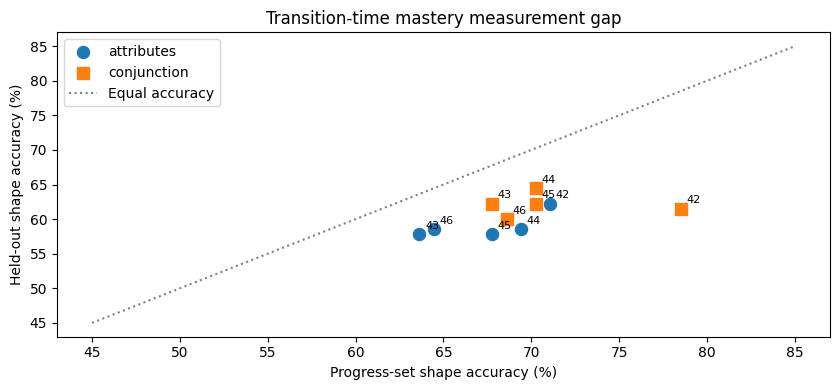

In [13]:
gate_gap = pd.DataFrame(gate_rows)
gate_gap['shape_gap_pp'] = gate_gap['shape_progress'] - gate_gap['shape_heldout']
gate_gap.to_csv(OUTPUT_DIR / 'gate_progress_heldout_gap.csv', index=False)
display(gate_gap[['seed', 'stage', 'step', 'reason', 'shape_progress',
                  'shape_heldout', 'shape_gap_pp']].round(2))
fig, ax = plt.subplots(figsize=(8.5, 4))
for stage, marker in [('attributes', 'o'), ('conjunction', 's')]:
    rows = gate_gap[gate_gap.stage == stage]
    ax.scatter(rows.shape_progress, rows.shape_heldout, marker=marker,
               s=75, label=stage)
    for _, r in rows.iterrows():
        ax.annotate(str(r.seed), (r.shape_progress, r.shape_heldout),
                    xytext=(4, 4), textcoords='offset points', fontsize=8)
ax.plot([45, 85], [45, 85], linestyle=':', color='gray', label='Equal accuracy')
ax.set(xlabel='Progress-set shape accuracy (%)',
       ylabel='Held-out shape accuracy (%)', title='Transition-time mastery measurement gap')
ax.legend()
plt.tight_layout()
save_figure(fig, 'progress_vs_heldout_at_transitions')
plt.show()

## 10. How large were the forgotten skills' worst drops?

A transition delta only measures the first interval after a stage change. During the full binding stage, record the **worst** observed decline in color, shape and conjunction relative to the pre-binding checkpoint; then measure recovery during common consolidation. Mastery seeds have different binding-start times, so the comparison is stage-aligned rather than solely global-time-aligned.

first_100_pp  max_drop_pp  end_stage_change_pp  \
policy      task                                                          
fixed_early color                0.31         0.47                 1.56   
            conjunction         -1.56         2.81                -0.16   
            shape                0.59         2.96                 3.85   
fixed_late  color               -0.62         1.72                -0.78   
            conjunction         -2.97         5.00                -2.66   
            shape               -1.33         5.33                 0.59   
mastery     color               -3.12         8.12                -5.00   
            conjunction         -5.16         6.41                -3.44   
            shape               -2.96         5.19                 0.74   

                         recovery_pp  
policy      task                      
fixed_early color               0.31  
            conjunction         1.41  
            shape               2.67  
fixed_late  color               0.78  
            conjunction         1.72  
            shape               1.04  
mastery     color               5.31  
            conjunction         2.97  
            shape               0.15

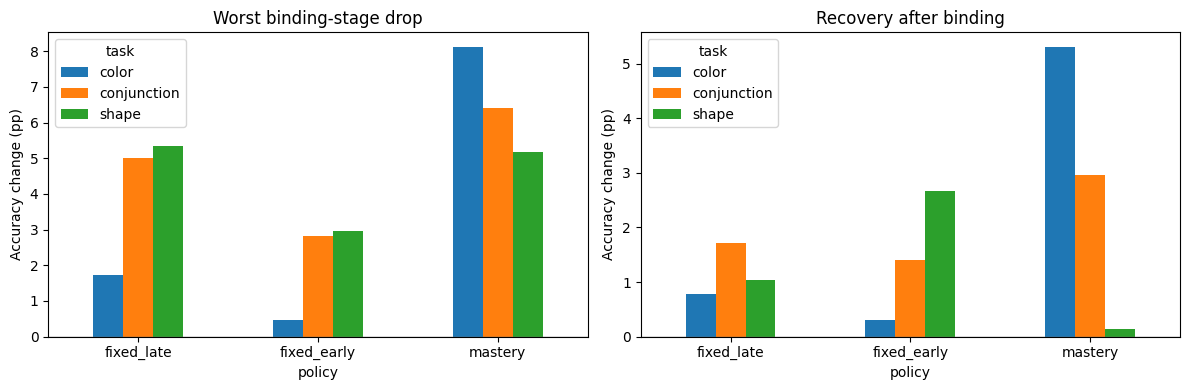

In [14]:
forget_rows = []
for r in runs:
    begin = r['transitions'][1]['step']
    end = r['transitions'][2]['step']
    snapshots = {h['step']: h for h in r['history']}
    samples = [h for h in r['history'] if begin < h['step'] <= end]
    for task in ('color', 'shape', 'conjunction'):
        before = 100 * snapshots[begin]['heldout_dev']['by_template'][task]
        values = [100 * h['heldout_dev']['by_template'][task] for h in samples]
        at_end = 100 * snapshots[end]['heldout_dev']['by_template'][task]
        at_final = 100 * r['final']['heldout_dev']['by_template'][task]
        forget_rows.append({'seed': r['seed'], 'policy': r['policy'],
                            'task': task, 'binding_start': begin,
                            'binding_end': end, 'first_100_pp': values[0] - before,
                            'max_drop_pp': max(0, before - min(values)),
                            'end_stage_change_pp': at_end - before,
                            'recovery_pp': at_final - at_end})
forgetting = pd.DataFrame(forget_rows)
forgetting.to_csv(OUTPUT_DIR / 'adaptive_forgetting_recovery.csv', index=False)
display(forgetting.groupby(['policy', 'task'])
        [['first_100_pp', 'max_drop_pp', 'end_stage_change_pp', 'recovery_pp']]
        .mean().round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, label in zip(axes, ('max_drop_pp', 'recovery_pp'),
                              ('Worst binding-stage drop', 'Recovery after binding')):
    table = forgetting.groupby(['policy', 'task'])[metric].mean().unstack('task')
    table.reindex(POLICIES).plot.bar(ax=ax, rot=0)
    ax.set(title=label, ylabel='Accuracy change (pp)')
    ax.axhline(0, color='gray', linewidth=1)
plt.tight_layout()
save_figure(fig, 'adaptive_forgetting_and_recovery')
plt.show()

## 11. Did OOD confidence improve with binding experience?

Plot OOD accuracy and BCE over global training time. BCE below the **50/50 baseline** \(-\log(0.5)\simeq0.693\) indicates a more favorable log-loss than uniform probabilities; higher accuracy alone does not establish that. Aggregate BCE cannot diagnose which individual errors are overconfident.

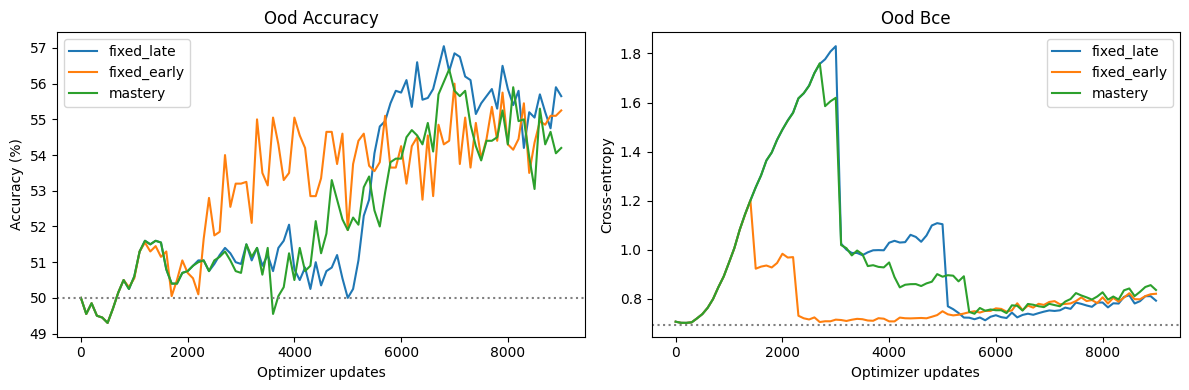

In [15]:
ood_rows = pd.DataFrame([{
    'seed': r['seed'], 'policy': r['policy'], 'step': h['step'],
    'ood_accuracy': 100 * h['ood_dev']['by_template']['pair'],
    'ood_bce': h['ood_dev']['loss']
} for r in runs for h in r['history']])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric, baseline in zip(axes, ('ood_accuracy', 'ood_bce'), (50, np.log(2))):
    for policy in POLICIES:
        group = ood_rows[ood_rows.policy == policy].groupby('step')[metric].mean()
        ax.plot(group.index, group.values, label=policy)
    ax.axhline(baseline, linestyle=':', color='gray')
    ax.set(title=metric.replace('_', ' ').title(), xlabel='Optimizer updates',
           ylabel='Accuracy (%)' if metric == 'ood_accuracy' else 'Cross-entropy')
    ax.legend()
plt.tight_layout()
save_figure(fig, 'mastery_ood_accuracy_bce_curves')
plt.show()

## What this study actually supports

We can establish whether the gate **triggered**, whether earlier binding exposure improved learning-curve efficiency, and whether older tasks temporarily declined. We cannot infer general compositional understanding from aggregate accuracy alone. The progress set was consulted repeatedly, and OOD-dev remains an exploratory split rather than a fresh final test. The next step is prediction-level shape and binding error analysis, not another arbitrary threshold sweep.